README.md:   0%|          | 0.00/4.95k [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  144MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 18.5MB            

data/validation-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 17.7MB            

data/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/1034 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/133 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/128 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['image_file_path', 'image', 'labels'],
        num_rows: 1034
    })
    validation: Dataset({
        features: ['image_file_path', 'image', 'labels'],
        num_rows: 133
    })
    test: Dataset({
        features: ['image_file_path', 'image', 'labels'],
        num_rows: 128
    })
})
Train: (450, 224, 224, 3) per class [150 150 150]
Test : (150, 224, 224, 3) per class [50 50 50] | ['Angular Leaf Spot', 'Bean Rust', 'Healthy'] | cpu


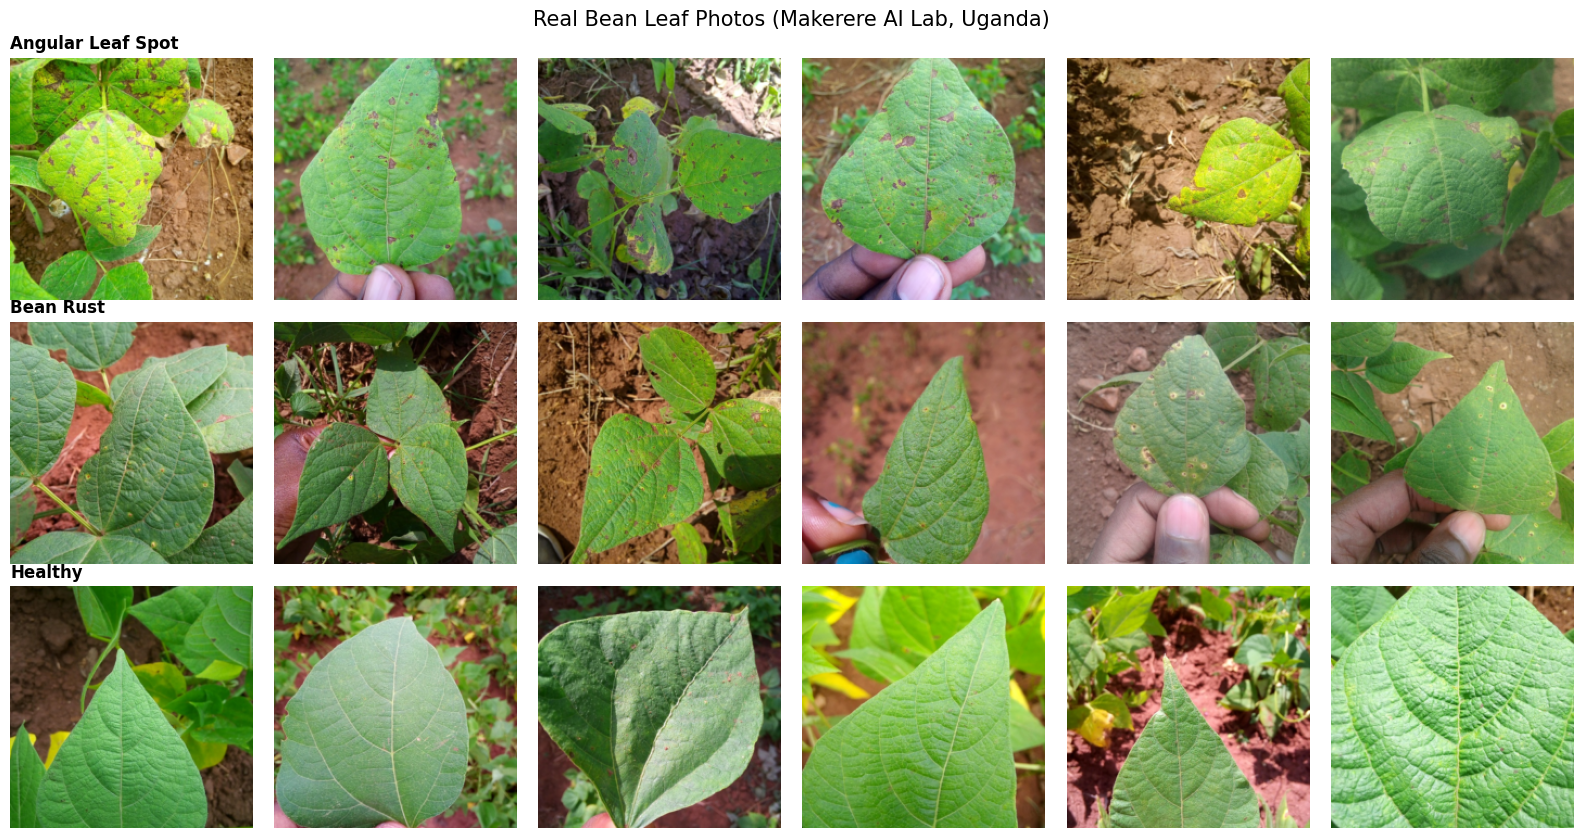

In [1]:
!pip install -q datasets

import os, time, copy, random
import numpy as np, cv2, matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
from PIL import Image
from datasets import load_dataset, concatenate_datasets

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
IMG = 224
N_TRAIN_PER_CLASS, N_TEST_PER_CLASS = 150, 50   # 450 train / 150 test

try:
    ds = load_dataset('AI-Lab-Makerere/beans')
except Exception as e:
    print('Primary load failed, using parquet branch:', e)
    ds = load_dataset('AI-Lab-Makerere/beans', revision='refs/convert/parquet')
print(ds)

LABEL_COL = 'labels' if 'labels' in ds['train'].features else 'label'
CLASSES = ds['train'].features[LABEL_COL].names
PRETTY = [c.replace('_', ' ').title() for c in CLASSES]

def balanced_subset(split, n_per_class, seed=SEED):
    rng = np.random.default_rng(seed)
    labels = np.array(list(split[LABEL_COL]))
    idx = np.concatenate([rng.choice(np.where(labels == c)[0], min(n_per_class, int((labels == c).sum())), replace=False)
                          for c in range(len(CLASSES))])
    rng.shuffle(idx)
    return split.select(idx.tolist())

def to_arrays(split):
    X = np.stack([np.array(ex['image'].convert('RGB').resize((IMG, IMG), Image.BILINEAR)) for ex in split])
    return X, np.array(list(split[LABEL_COL]))

train_hf = balanced_subset(ds['train'], N_TRAIN_PER_CLASS)
test_hf = balanced_subset(concatenate_datasets([ds['validation'], ds['test']]), N_TEST_PER_CLASS)
X_tr, y_tr = to_arrays(train_hf)
X_te, y_te = to_arrays(test_hf)
print(f'Train: {X_tr.shape} per class {np.bincount(y_tr)}')
print(f'Test : {X_te.shape} per class {np.bincount(y_te)} | {PRETTY} | {DEVICE}')

fig, axes = plt.subplots(3, 6, figsize=(16, 8.5))
for c in range(3):
    for j, i in enumerate(np.where(y_tr == c)[0][:6]):
        axes[c, j].imshow(X_tr[i]); axes[c, j].axis('off')
    axes[c, 0].set_title(PRETTY[c], loc='left', fontweight='bold', fontsize=12)
plt.suptitle('Real Bean Leaf Photos (Makerere AI Lab, Uganda)', fontsize=15); plt.tight_layout(); plt.show()

Downloading: "https://download.pytorch.org/models/mobilenet_v2-7ebf99e0.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v2-7ebf99e0.pth


100%|██████████| 13.6M/13.6M [00:00<00:00, 189MB/s]

MobileNetV2 parameters: 2,227,715


Epoch 01/10 | loss 0.9180/0.7498 | acc 0.589/0.707 | 87.1s
Epoch 02/10 | loss 0.5880/0.5359 | acc 0.840/0.887 | 77.7s
Epoch 03/10 | loss 0.4629/0.5925 | acc 0.927/0.847 | 76.0s
Epoch 04/10 | loss 0.4299/0.5014 | acc 0.940/0.913 | 75.6s
Epoch 05/10 | loss 0.3879/0.4816 | acc 0.969/0.933 | 84.8s
Epoch 06/10 | loss 0.4137/0.4923 | acc 0.962/0.893 | 85.0s
Epoch 07/10 | loss 0.3767/0.5488 | acc 0.976/0.887 | 80.0s
Epoch 08/10 | loss 0.3922/0.4846 | acc 0.960/0.913 | 78.3s
Epoch 09/10 | loss 0.3835/0.4673 | acc 0.958/0.913 | 77.3s
Epoch 10/10 | loss 0.3794/0.4600 | acc 0.964/0.920 | 77.3s

Final test accuracy on real images: 92.00%


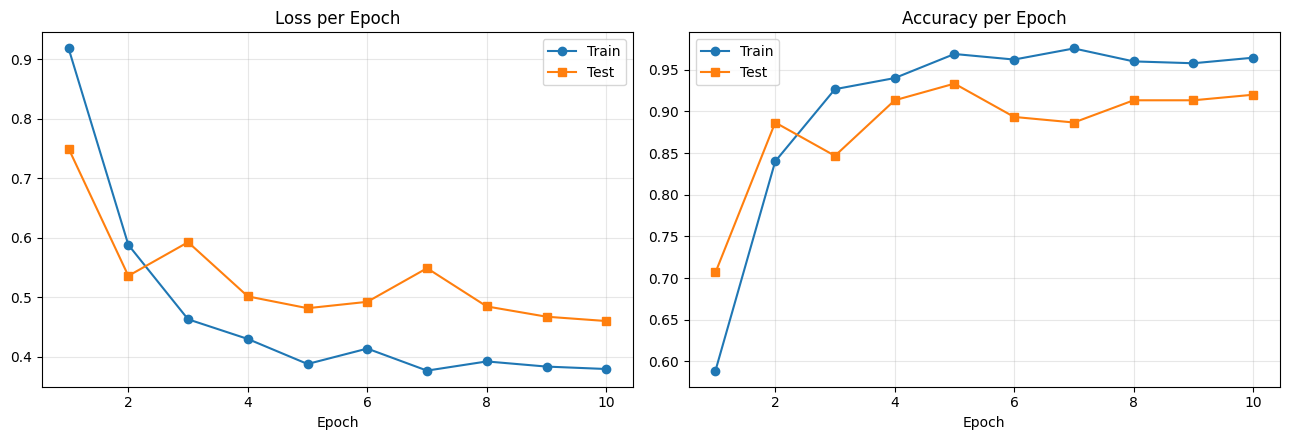

In [2]:
import torchvision
from torchvision import transforms as T
from torch.utils.data import Dataset, DataLoader

class LeafPreprocessor:
    """Edge-preserving denoise + CLAHE on L channel."""
    def __init__(self, clip=1.5, tile=8):
        self.clahe = cv2.createCLAHE(clipLimit=clip, tileGridSize=(tile, tile))
    def __call__(self, img):
        img = cv2.bilateralFilter(img, 5, 40, 40)
        lab = cv2.cvtColor(img, cv2.COLOR_RGB2LAB)
        lab[..., 0] = self.clahe.apply(lab[..., 0])
        return cv2.cvtColor(lab, cv2.COLOR_LAB2RGB)

prep = LeafPreprocessor()
X_tr_p = np.stack([prep(x) for x in X_tr])
X_te_p = np.stack([prep(x) for x in X_te])

MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
TF_TRAIN = T.Compose([T.ToPILImage(), T.RandomResizedCrop(IMG, scale=(0.7, 1.0)), T.RandomHorizontalFlip(),
                      T.RandomVerticalFlip(), T.RandomRotation(20), T.ColorJitter(0.2, 0.2, 0.15),
                      T.ToTensor(), T.Normalize(MEAN, STD)])
TF_TEST = T.Compose([T.ToPILImage(), T.ToTensor(), T.Normalize(MEAN, STD)])

class LeafDataset(Dataset):
    def __init__(self, X, y, tf): self.X, self.y, self.tf = X, y, tf
    def __len__(self): return len(self.y)
    def __getitem__(self, i): return self.tf(self.X[i]), int(self.y[i])

train_dl = DataLoader(LeafDataset(X_tr_p, y_tr, TF_TRAIN), batch_size=32, shuffle=True, num_workers=2)
test_ds = LeafDataset(X_te_p, y_te, TF_TEST)
test_dl = DataLoader(test_ds, batch_size=64, num_workers=2)

def build_model(n_classes, pretrained=True):
    m = torchvision.models.mobilenet_v2(weights='DEFAULT' if pretrained else None)
    m.classifier[1] = nn.Linear(m.last_channel, n_classes)
    return m

class FineTuner:
    def __init__(self, model, epochs=10, lr_backbone=3e-4, lr_head=1e-3):
        self.model, self.epochs = model.to(DEVICE), epochs
        self.opt = torch.optim.AdamW([{'params': model.features.parameters(), 'lr': lr_backbone},
                                      {'params': model.classifier.parameters(), 'lr': lr_head}], weight_decay=1e-4)
        self.sched = torch.optim.lr_scheduler.CosineAnnealingLR(self.opt, T_max=epochs)
        self.crit = nn.CrossEntropyLoss(label_smoothing=0.1)
        self.hist = {k: [] for k in ['tr_loss', 'te_loss', 'tr_acc', 'te_acc']}

    def run_epoch(self, dl, train):
        self.model.train(train); tot, correct, loss_sum = 0, 0, 0.0
        with torch.set_grad_enabled(train):
            for xb, yb in dl:
                xb, yb = xb.to(DEVICE), yb.to(DEVICE)
                out = self.model(xb); loss = self.crit(out, yb)
                if train: self.opt.zero_grad(); loss.backward(); self.opt.step()
                loss_sum += loss.item() * len(yb); correct += (out.argmax(1) == yb).sum().item(); tot += len(yb)
        return loss_sum / tot, correct / tot

    def fit(self, tr, te):
        for ep in range(1, self.epochs + 1):
            t0 = time.time()
            trl, tra = self.run_epoch(tr, True); tel, tea = self.run_epoch(te, False); self.sched.step()
            for k, v in zip(self.hist, (trl, tel, tra, tea)): self.hist[k].append(v)
            print(f'Epoch {ep:02d}/{self.epochs} | loss {trl:.4f}/{tel:.4f} | acc {tra:.3f}/{tea:.3f} | {time.time()-t0:.1f}s')
        return self.hist

model = build_model(len(CLASSES))
print(f'MobileNetV2 parameters: {sum(p.numel() for p in model.parameters()):,}')
hist = FineTuner(model, epochs=10).fit(train_dl, test_dl)
print(f'\nFinal test accuracy on real images: {hist["te_acc"][-1]:.2%}')

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
for a, key, name in [(ax[0], 'loss', 'Loss'), (ax[1], 'acc', 'Accuracy')]:
    a.plot(range(1, 11), hist[f'tr_{key}'], 'o-', label='Train')
    a.plot(range(1, 11), hist[f'te_{key}'], 's-', label='Test')
    a.set_title(f'{name} per Epoch'); a.set_xlabel('Epoch'); a.grid(alpha=0.3); a.legend()
plt.tight_layout(); plt.show()

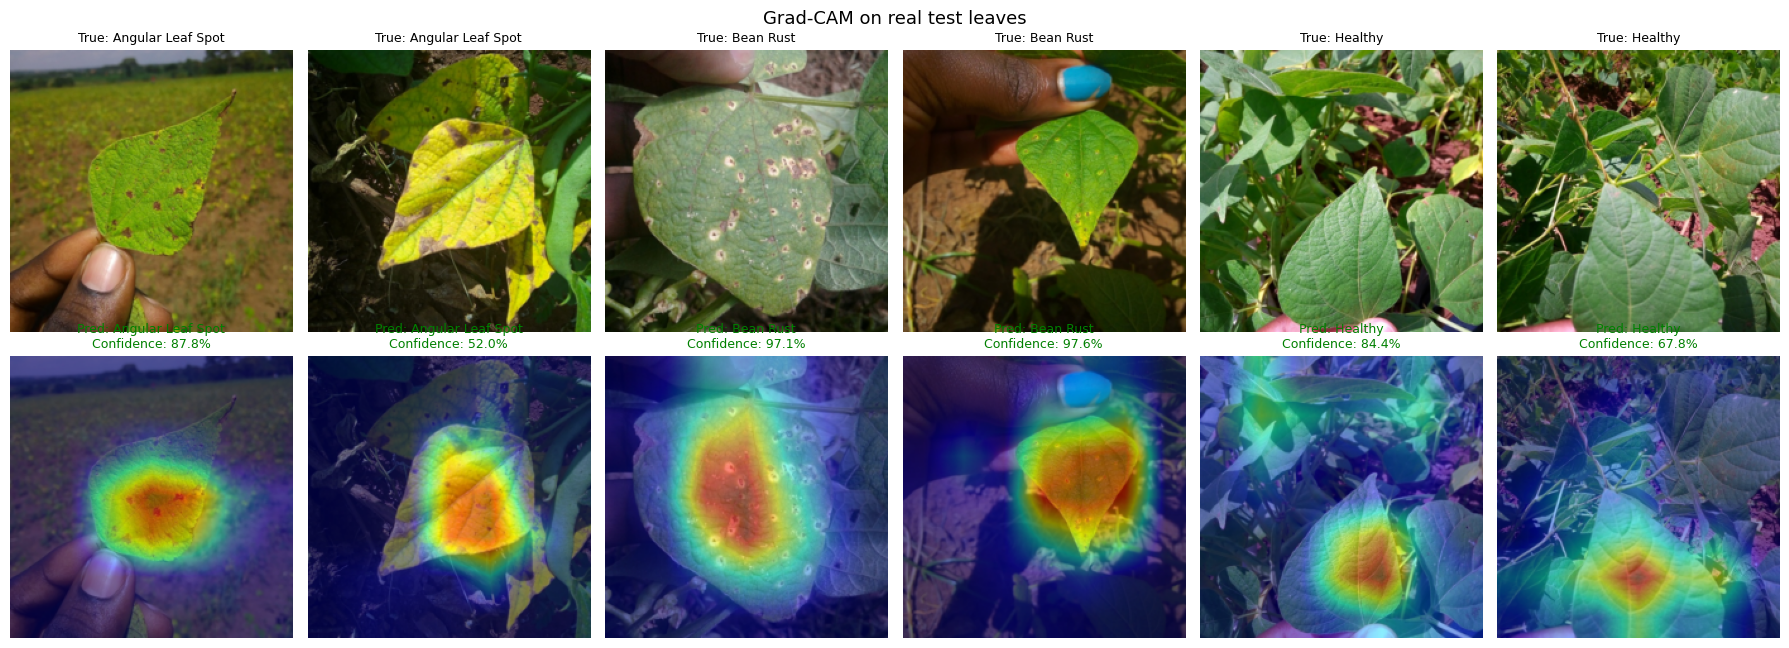

In [3]:
class GradCAM:
    def __init__(self, model, layer):
        self.model, self.acts, self.grads = model, None, None
        self.handle = layer.register_forward_hook(self._hook)
    def _hook(self, module, inp, out):
        self.acts = out
        if out.requires_grad: out.register_hook(lambda g: setattr(self, 'grads', g))
    def __call__(self, x, cls=None):
        self.model.eval()
        logits = self.model(x); probs = F.softmax(logits, 1)
        cls = int(logits.argmax(1)) if cls is None else cls
        self.model.zero_grad(); logits[0, cls].backward()
        weights = self.grads.mean(dim=(2, 3), keepdim=True)
        cam = F.relu((weights * self.acts).sum(1, keepdim=True))
        cam = F.interpolate(cam, size=x.shape[-2:], mode='bilinear', align_corners=False)[0, 0]
        cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
        return cam.detach().cpu().numpy(), cls, probs[0, cls].item()
    def remove(self): self.handle.remove()

def cam_overlay(img, cam, alpha=0.45):
    heat = cv2.cvtColor(cv2.applyColorMap(np.uint8(255 * cam), cv2.COLORMAP_JET), cv2.COLOR_BGR2RGB)
    return np.uint8((1 - alpha) * img + alpha * heat)

gradcam = GradCAM(model, model.features[-1])

demo = [i for c in range(len(CLASSES)) for i in np.where(y_te == c)[0][:2]]
fig, axes = plt.subplots(2, len(demo), figsize=(3 * len(demo), 6.6))
for j, i in enumerate(demo):
    cam, pc, conf = gradcam(test_ds[i][0].unsqueeze(0).to(DEVICE))
    axes[0, j].imshow(X_te[i]); axes[0, j].set_title(f'True: {PRETTY[y_te[i]]}', fontsize=9)
    axes[1, j].imshow(cam_overlay(X_te[i], cam))
    axes[1, j].set_title(f'Pred: {PRETTY[pc]}\nConfidence: {conf:.1%}', fontsize=9,
                         color='green' if pc == y_te[i] else 'red')
    axes[0, j].axis('off'); axes[1, j].axis('off')
plt.suptitle('Grad-CAM on real test leaves', fontsize=13); plt.tight_layout(); plt.show()

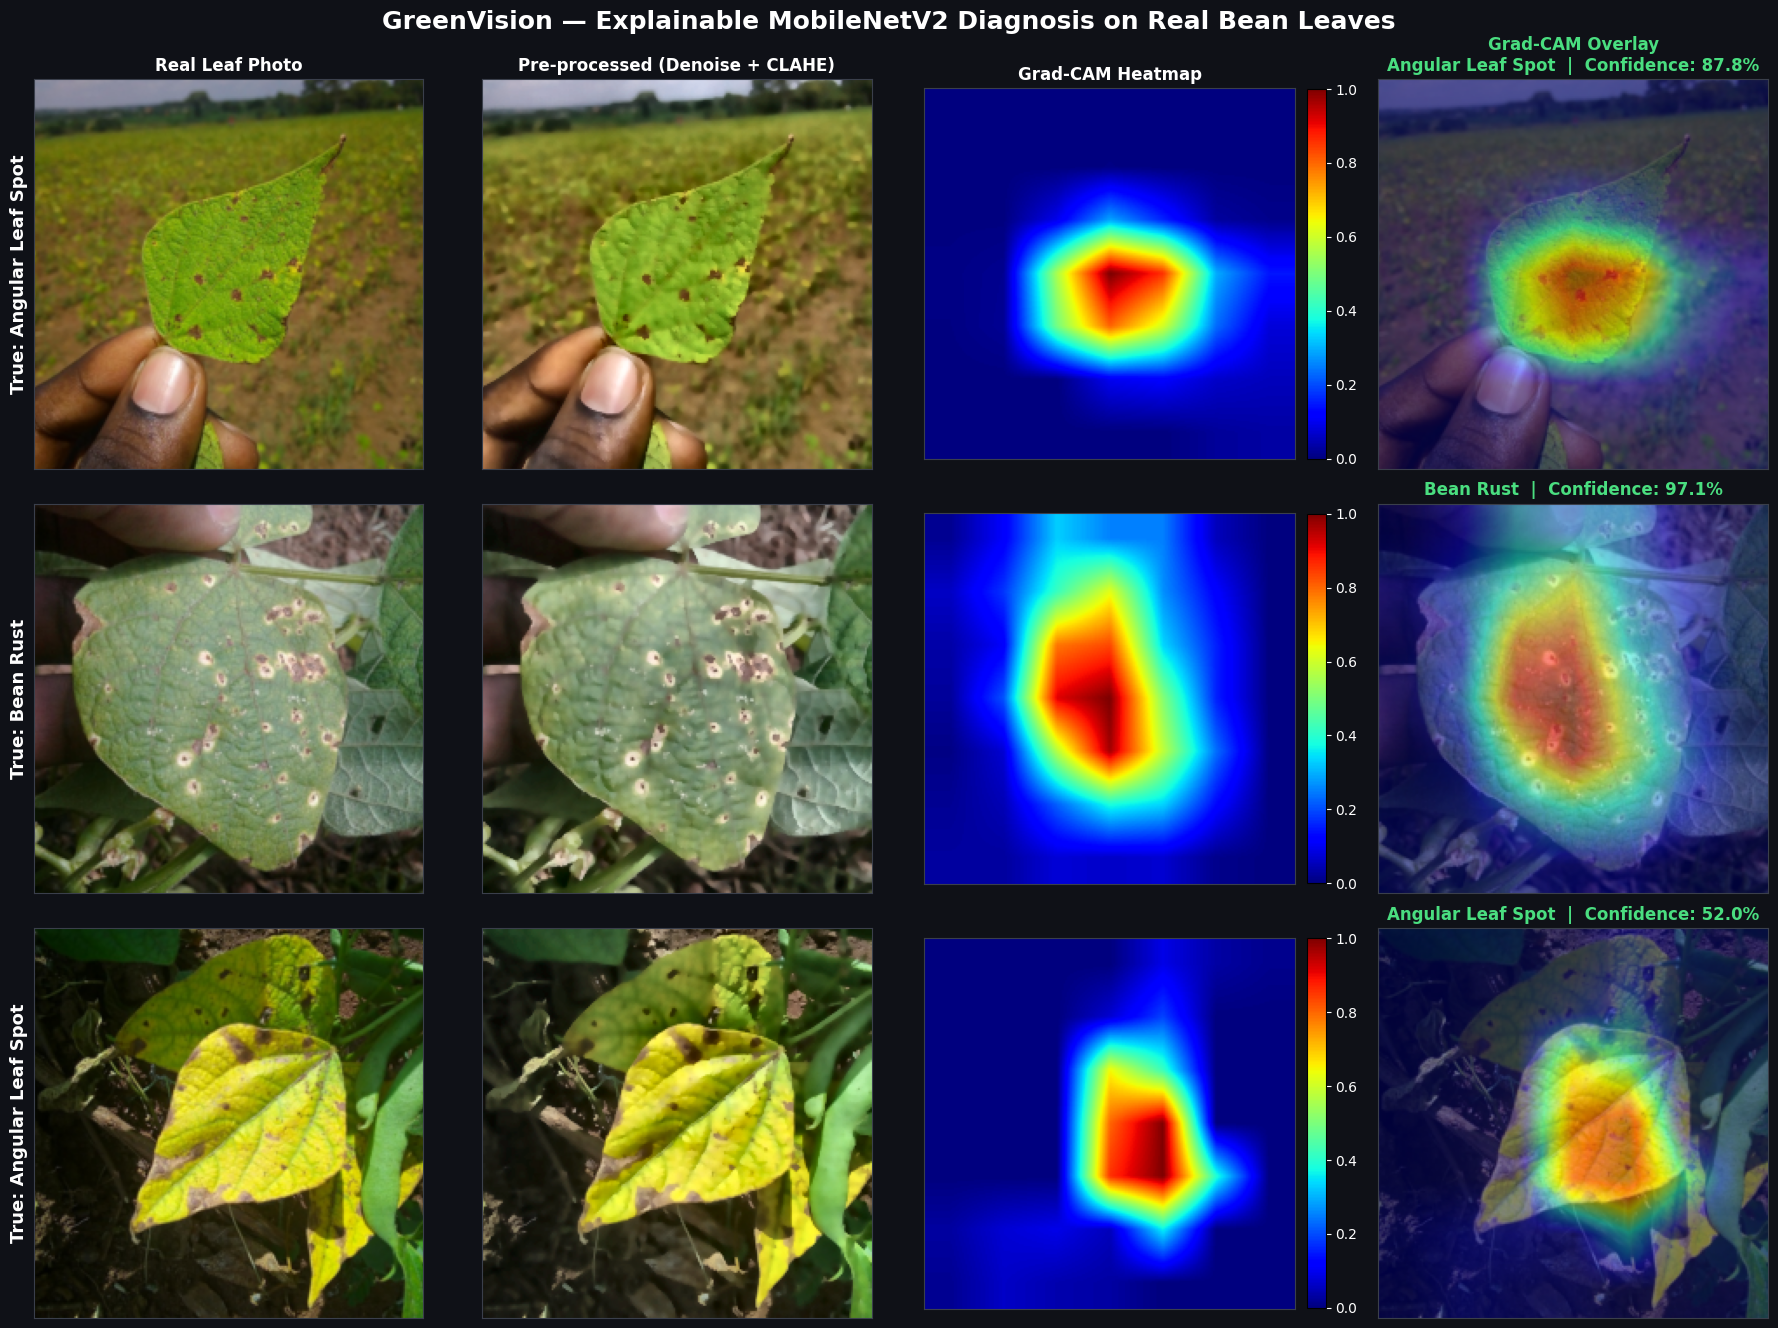

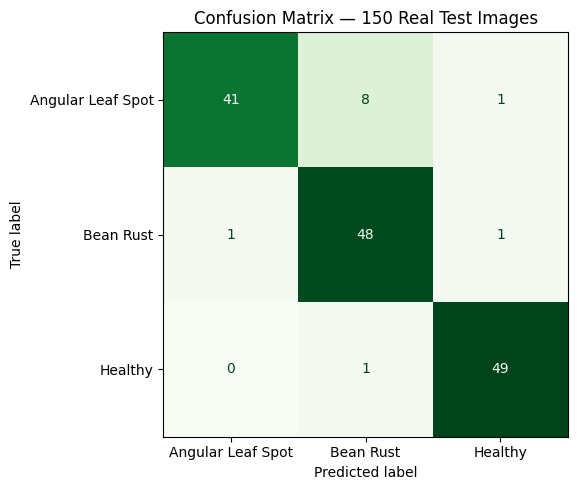

                   precision    recall  f1-score   support

Angular Leaf Spot      0.976     0.820     0.891        50
        Bean Rust      0.842     0.960     0.897        50
          Healthy      0.961     0.980     0.970        50

         accuracy                          0.920       150
        macro avg      0.926     0.920     0.920       150
     weighted avg      0.926     0.920     0.920       150


      GreenVision — Real-Data Edge Evaluation Report
                           Metric        Value
  Test Accuracy (150 real images)       92.00%
                   Macro F1-Score       0.9196
                 Model Parameters    2,227,715
                Model Size (FP32)      8.73 MB
Inference Latency — CPU, 1 thread     31.07 ms
          Inference Latency — GPU N/A (no GPU)
       Throughput — CPU, 1 thread     32.2 FPS
Saved: gradcam_results.png, greenvision_mobilenetv2.pt


In [4]:
# ============================================================
# Cell 4 — Final Dashboard (gradcam_results.png) + Evaluation Table
# ============================================================
import pandas as pd
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

model.eval(); probs = []
with torch.no_grad():
    for xb, _ in test_dl: probs.append(F.softmax(model(xb.to(DEVICE)), 1).cpu())
probs = torch.cat(probs).numpy(); y_pred = probs.argmax(1)

# ---- pick 3 real DISEASED test leaves (both diseases represented, correctly classified when possible) ----
healthy = CLASSES.index('healthy') if 'healthy' in CLASSES else -1
disease = [c for c in range(len(CLASSES)) if c != healthy]
pool = {c: [i for i in np.where(y_te == c)[0] if y_pred[i] == c] or list(np.where(y_te == c)[0]) for c in disease}
picks, k = [], 0
while len(picks) < 3:
    for c in disease:
        if k < len(pool[c]) and len(picks) < 3: picks.append(pool[c][k])
    k += 1

# ---------- 1) 4-column Grad-CAM dashboard ----------
BG, FG = '#0f1117', 'white'
cols = ['Real Leaf Photo', 'Pre-processed (Denoise + CLAHE)', 'Grad-CAM Heatmap', 'Grad-CAM Overlay']
fig, axes = plt.subplots(3, 4, figsize=(18, 13.5), facecolor=BG)
for r, i in enumerate(picks):
    cam, pc, conf = gradcam(test_ds[i][0].unsqueeze(0).to(DEVICE))
    panels = [X_te[i], X_te_p[i], cam, cam_overlay(X_te[i], cam)]
    for c, (ax, pnl) in enumerate(zip(axes[r], panels)):
        if c == 2:
            im = ax.imshow(pnl, cmap='jet', vmin=0, vmax=1)
            cb = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.03); cb.ax.tick_params(colors=FG)
        else:
            ax.imshow(pnl)
        ax.set_xticks([]); ax.set_yticks([])
        for s in ax.spines.values(): s.set_color('#3a3f4b')
        title = cols[c] if r == 0 else ''
        if c == 3:
            title += ('\n' if title else '') + f'{PRETTY[pc]}  |  Confidence: {conf * 100:.1f}%'
            ax.set_title(title, color='#4ade80' if pc == y_te[i] else '#f87171', fontsize=12, fontweight='bold')
        else:
            ax.set_title(title, color=FG, fontsize=12, fontweight='bold')
    axes[r, 0].set_ylabel(f'True: {PRETTY[y_te[i]]}', color=FG, fontsize=13, fontweight='bold')
fig.suptitle('GreenVision — Explainable MobileNetV2 Diagnosis on Real Bean Leaves',
             color=FG, fontsize=18, fontweight='bold')
plt.tight_layout()
plt.savefig('gradcam_results.png', dpi=300, bbox_inches='tight', facecolor=BG)
plt.show()

# ---------- 2) Confusion matrix + per-class report ----------
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay(confusion_matrix(y_te, y_pred), display_labels=PRETTY).plot(cmap='Greens', ax=ax, colorbar=False)
ax.set_title('Confusion Matrix — 150 Real Test Images'); plt.tight_layout(); plt.show()
print(classification_report(y_te, y_pred, target_names=PRETTY, digits=3))


# ---------- 3) Edge profiling ----------
@torch.no_grad()
def latency_ms(m, device, runs=100, warmup=10):
    m = m.to(device).eval(); x = torch.randn(1, 3, IMG, IMG, device=device); t = []
    for _ in range(warmup): m(x)
    for _ in range(runs):
        if device.type == 'cuda': torch.cuda.synchronize()
        t0 = time.perf_counter(); m(x)
        if device.type == 'cuda': torch.cuda.synchronize()
        t.append((time.perf_counter() - t0) * 1e3)
    return float(np.median(t))

edge_model = build_model(len(CLASSES), pretrained=False)       # clean copy without Grad-CAM hooks
edge_model.load_state_dict({k: v.cpu() for k, v in model.state_dict().items()}); edge_model.eval()
torch.save(edge_model.state_dict(), 'greenvision_mobilenetv2.pt')

n_thr = torch.get_num_threads(); torch.set_num_threads(1)       # simulate a single-core edge CPU
cpu_ms = latency_ms(edge_model, torch.device('cpu'))
torch.set_num_threads(n_thr)
gpu_ms = latency_ms(copy.deepcopy(edge_model), torch.device('cuda')) if torch.cuda.is_available() else None

report = pd.DataFrame({
    'Metric': ['Test Accuracy (150 real images)', 'Macro F1-Score', 'Model Parameters', 'Model Size (FP32)',
               'Inference Latency — CPU, 1 thread', 'Inference Latency — GPU', 'Throughput — CPU, 1 thread'],
    'Value': [f'{accuracy_score(y_te, y_pred):.2%}', f'{f1_score(y_te, y_pred, average="macro"):.4f}',
              f'{sum(p.numel() for p in edge_model.parameters()):,}',
              f'{os.path.getsize("greenvision_mobilenetv2.pt") / 1024 ** 2:.2f} MB',
              f'{cpu_ms:.2f} ms', f'{gpu_ms:.2f} ms' if gpu_ms else 'N/A (no GPU)', f'{1000 / cpu_ms:.1f} FPS']})
print('\n' + '=' * 64 + '\n      GreenVision — Real-Data Edge Evaluation Report\n' + '=' * 64)
print(report.to_string(index=False))
print('=' * 64 + '\nSaved: gradcam_results.png, greenvision_mobilenetv2.pt')